# Parameters

In [1]:
%matplotlib inline
import sys
from prem import *
import scipy.integrate as si
from matplotlib.colors import LinearSegmentedColormap
Re=6.3781e8 # Earth radius
pi=np.pi
c=3e10 # cm/s
lmin = 0.5588391918010813
lmax = 0.6411608081989186
zmax = 0.2195243103942331
epsilon_0=8.8e-12
m_e=9.1e-31
B0=156
box=[48,256]

# Dipole Magnetic field

In [5]:
# mode = 3  # '3D dipole'
mode = 2  # '2D dipole'
zmin = -zmax
X = np.linspace(lmin, lmax, 200)
Z = np.linspace(zmin, zmax, 300)
xmesh, zmesh = np.meshgrid(X,Z)

Bx = np.zeros( (len(Z), len(X)) )
Bz = np.zeros( (len(Z), len(X)) )
B = np.zeros( (len(Z), len(X)) )
Theta = np.zeros( (len(Z), len(X)) )

R = np.sqrt(xmesh**2+zmesh**2)
Theta = pi/2-np.arctan2(zmesh, xmesh)
M_sgn = -1

if mode==3:
  Bx = M_sgn*(B0/R**3)*3*np.sin(Theta)*np.cos(Theta)
  Bz = M_sgn*(B0/R**3)*(3*np.cos(Theta)**2-1)
  L = R/np.sin(Theta)**2
  Beq = B0/L**3
  Beqm = B0/(L[150,-1]**3)
elif mode==2:  # this 2D mode is used for simulations
  A=B0/3
  deno = (xmesh**2+zmesh**2)**2
  Bx = M_sgn*A*2*xmesh*zmesh/deno
  Bz = M_sgn*A*(zmesh**2-xmesh**2)/deno
  L = R/np.sin(Theta)
  Beq = B0/(3*L**2)
  Beqm = B0/(3*L[150,-1]**2)
#   Beqm = B0/(L0**3)
B = np.sqrt(Bx**2+Bz**2)

# Field Mask

In [6]:
mcf = 0.1; Lx = 48.0; Ly = 256.0; dx = 15.0; dy = 20.0; nx = 481;ny = 1025
x = np.linspace(0.0, Lx, nx); y = np.linspace(0.0, Ly, ny)
X, Y = np.meshgrid(x, y)
# Initialize individual masks
fm_left = np.ones_like(X)
fm_bottom = np.ones_like(X)
fm_top = np.ones_like(X)

# 1. Left-boundary mask: 0 <= x <= 15
left = X <= dx
taper_x = (X[left] - dx) / dx
taper_y = (Y[left] - Ly / 2.0) / (Ly / 2.0)
fm_left[left] = 1.0 - mcf**2 * taper_x**2 * taper_y**2

# 2. Bottom-boundary mask: 0 <= y <= 20
bottom = Y <= dy
taper_x = (X[bottom] - Lx) / Lx
taper_y = (Y[bottom] - dy) / dy
fm_bottom[bottom] = 1.0 - mcf**2 * taper_x**2 * taper_y**2

# 3. Top-boundary mask: 236 <= y <= 256
top = Y >= (Ly - dy)
taper_x = (X[top] - Lx) / Lx
taper_y = (Y[top] - (Ly - dy)) / dy
fm_top[top] =1-mcf**2 * taper_x**2 * taper_y**2

# 4. Combine the masks multiplicatively
fm = fm_left * fm_bottom * fm_top

# Ray Tracing

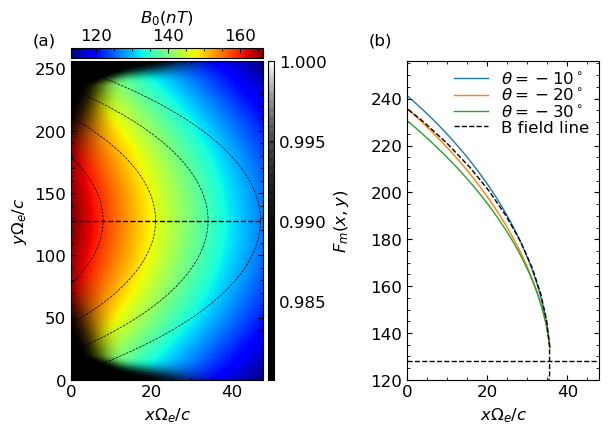

In [4]:
cmap = LinearSegmentedColormap.from_list('transparent_white', [(0, (0, 0, 0, 1)), (1, (0, 0, 0, 0))])
Re=6.3781e8 # Earth radius
plt.rc('lines',linewidth=1.0)
plt.rc('font',size=12)
def mag_field_model_2d(x,y,z):
    '''Dipole magnetic field, in Gauss '''
    # b_eq=-0.3/L**3 
    b_eq = 1.56e-3 # use field at L~6
    r=np.sqrt(x**2+z**2)
    theta=np.arccos((z/r))
    L=r/np.sin(theta)
    A = - b_eq * L**2
    deno = (x**2+z**2)**2
    bx = A*2*x*z/deno
    by = 0
    bz = A*(z**2-x**2)/deno
    return bx, by, bz

def density_model_2d(x,y,z):
    '''in /cc '''
    return 4 # use density at L~6

def plasma_freq(n0,bx,by,bz):
    b0=np.sqrt(bx**2+by**2+bz**2)
    wce=1.76e7*b0
    wpe=5.64e4*np.sqrt(n0)
    return wce, wpe

def disper_k(w,th,x,y,z):
    bx,by,bz=mag_field_model_2d(x,y,z)
    n0=density_model_2d(x,y,z)
    wce,wpe=plasma_freq(n0,bx,by,bz)
    return np.sqrt(1.-wpe**2/w/(w-wce*np.cos(th)))*w/c

def disper_w(x,y,z,kx,ky,kz):
    # return w when given wavenumber k
    bx,by,bz=mag_field_model_2d(x,y,z)
    n0=density_model_2d(x,y,z)
    wce,wpe=plasma_freq(n0,bx,by,bz)
    # print('wpe/wce=', wpe/wce)
    b0=np.sqrt(bx**2+by**2+bz**2) # earlier this was not defined
    kpara=(kx*bx+ky*by+kz*bz)/b0
    kk=np.sqrt(kx**2+ky**2+kz**2)
    if kpara>kk: # numerical error
        kpara=kk
    th=np.arccos(kpara/kk)

    coeff=[1., -wce*np.cos(th), -wpe**2-c**2*kk**2, c**2*kk**2*wce*np.cos(th)]
    ws=np.roots(coeff)
    for w in ws:
        # pick the solution for whistler
        if 0<w<wce: return w

def dw(x,y,z,kx,ky,kz):
    # numerical evaluation dw/dr and dw/dk
    bx,by,bz=mag_field_model_2d(x,y,z)
    b0=np.sqrt(bx**2+by**2+bz**2)
    n0=density_model_2d(x,y,z)
    de=5.31e5/np.sqrt(n0)
    w0=disper_w(x,y,z,kx,ky,kz)

    dk=0.001/de
    dx=0.001*Re

    w1=disper_w(x+dx,y,z,kx,ky,kz)
    w2=disper_w(x,y+dx,z,kx,ky,kz)
    w3=disper_w(x,y,z+dx,kx,ky,kz)
    w4=disper_w(x,y,z,kx+dk,ky,kz)
    w5=disper_w(x,y,z,kx,ky+dk,kz)
    w6=disper_w(x,y,z,kx,ky,kz+dk) 

    return (w1-w0)/dx, (w2-w0)/dx, (w3-w0)/dx, (w4-w0)/dk, (w5-w0)/dk, (w6-w0)/dk

def ray_func(t,s):
    d1,d2,d3,d4,d5,d6=dw(s[0],s[1],s[2],s[3],s[4],s[5])
    sdot=[d4, d5, d6, -d1,-d2,-d3]
    return sdot

l = 0.62
x=l*Re
y=0
z=0.01*Re

bx,by,bz=mag_field_model_2d(x,y,z)
n0=density_model_2d(x,y,z)
de=5.31e5/np.sqrt(n0)
b0=np.sqrt(bx**2+by**2+bz**2)
wce=1.76e7*b0
w=0.4*wce
plt.figure(figsize=[6,4.25])
plt.subplot(122)
for th in [-pi/180*10,-pi/180*20,-pi/180*30]:
    k=disper_k(w,th,x,y,z)
    kx=k*np.sin(th)
    ky=0
    kz=k*np.cos(th)
    tmax=150*2*pi/wce
    t=np.linspace(0., tmax, 100)
    sol=si.solve_ivp(ray_func, [0, tmax], [x, y, z, kx, ky, kz], t_eval=t, atol=1e-12)
    plt.plot((sol.y[0,:]/Re-lmin)*(48/(lmax-lmin)), (sol.y[2,:]/Re*128/zmax+128),'-',label=r'$\theta=%d^\circ$'%(th/pi*180))
    
plt.xlabel(r'$x\Omega_e/c$')
th=np.linspace(0,pi,100)
r=l*np.sin(th)
x=(r*np.sin(th)-lmin)*(48/(lmax-lmin))
z=r*np.cos(th)*128/zmax+256/2
plt.plot(x,z,'k--', linewidth=1, label='B field line')
plt.legend(loc='upper right',ncol=1,borderpad=.1,
             labelspacing=.01,prop={'size':12},frameon=False)
plt.axhline(128,ls='--',color='k')
plt.xlim(0,48)
plt.ylim(120,256)
ax=plt.gca()
pltmd(ax,'k')
plt.text(-.2,1.05,'(b)',transform=ax.transAxes)
lmin, lmax, zmax = .55, .64, .21
l_list = np.linspace(lmin, lmax, 5)
plt.subplot(121)
im=plt.imshow(B, cmap='jet',aspect='auto',extent=[0,48,0,256])
ax1=plt.gca()
cbar(im,ax1,[0, 1.01, 1.0, .03],'horizontal',label='$B_0(nT)$')
plot_fld_lines_sim(ax1,l_list)
ax1.set_xlim(0, 48);ax1.set_ylim(0, 256)
plt.xlabel(r'$x\Omega_e/c$')
plt.ylabel(r'$y\Omega_e/c$')
fmm=plt.contour(X, Y, fm,levels=1000,cmap=cmap)
cbar(fmm,ax1,[1.025, .0, .03, 1],'vertical',label='$F_m(x,y)$',ticks=[.985,.99,.995,1])
plt.axhline(128,color='k',ls='--')
plt.text(-.2,1.05,'(a)',transform=ax1.transAxes)
pltmd(ax1,'k')
plt.subplots_adjust(left=.11,right=.99,top=.850,bottom=0.10, wspace=.75)
plt.show()